In [65]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
spotifyDataOriginal = pd.read_csv("/Users/dylankiwanuka/Desktop/Notebook_Analysis/Notebook-Analysis-Project/data/spotify_songs.csv")
spotifyData = pd.read_csv("/Users/dylankiwanuka/Desktop/Notebook_Analysis/Notebook-Analysis-Project/data/spotify_songs.csv")
spotifyData.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


## Stage 1: Dataset Seletion

**Dataset:** 30000 Spotify Songs
**Source:** [Kaggle](https://www.kaggle.com/datasets/joebeachcapital/30000-spotify-songs/data?select=readme.md)

### Why I chose this dataset
This dataset combines Spotify's popularity score with audio features such as danceability, energy and valence, along with genre labels. That makes it possible to look at what popular songs have in common, both overall and within individual genres. With over 32,000 tracks, it is large enough to support meaningful analysis.

### Questions I aim to answer
1. What audio features (e.g. valence, danceability, energy, tempo) are most associated with a hit song?
2. Is there a key or mode that popular songs favour?
3. Do the features of a hit song differ by genre (e.g. rap, R&B)?


## Stage 2: Initial Data Exploration

**Size:** 32,833 rows and 23 columns

### Column Names and Data Types

| Column | Data Type |
|---|---|
| track_id | str |
| track_name | str |
| track_artist | str |
| track_popularity | int64 |
| track_album_id | str |
| track_album_name | str |
| track_album_release_date | str |
| playlist_name | str |
| playlist_id | str |
| playlist_genre | str |
| playlist_subgenre | str |
| danceability | float64 |
| energy | float64 |
| key | int64 |
| loudness | float64 |
| mode | int64 |
| speechiness | float64 |
| acousticness | float64 |
| instrumentalness | float64 |
| liveness | float64 |
| valence | float64 |
| tempo | float64 |
| duration_ms | int64 |

In [5]:
#List all columns and their Datatype:
spotifyData.dtypes

track_id                        str
track_name                      str
track_artist                    str
track_popularity              int64
track_album_id                  str
track_album_name                str
track_album_release_date        str
playlist_name                   str
playlist_id                     str
playlist_genre                  str
playlist_subgenre               str
danceability                float64
energy                      float64
key                           int64
loudness                    float64
mode                          int64
speechiness                 float64
acousticness                float64
instrumentalness            float64
liveness                    float64
valence                     float64
tempo                       float64
duration_ms                   int64
dtype: object

In [6]:
#Count number of rows and columns
spotifyData.shape

(32833, 23)

## Stage 3: Data Cleaning

- Addressing Duplicates


In [7]:
#No rows are exactly the same
spotifyData.duplicated().sum()

np.int64(0)

In [8]:
# The 4,477 is the number of extra rows whose track_id already appeared earlier in the dataset, so the first copy of each track isn’t counted.
spotifyData.duplicated(subset=["track_id"]).sum()

np.int64(4477)

In [9]:
pd.set_option("display.max_columns", None)
# keep=False marks ALL copies, so you can see the whole group side by side
dupes = spotifyData[spotifyData.duplicated(subset=["track_id"], keep=False)]
dupes.sort_values("track_id").head(10)

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
32084,00Gu3RMpDW2vO9PjlMVFDL,Hide Away (feat. Envy Monroe),Blasterjaxx,42,5pqG85igfoeWcCDIsSi9x7,Hide Away (feat. Envy Monroe),2019-06-21,Epic Bass Drops | Best House Mixes,4IS7o1utOzhimFEFnj9gmu,edm,progressive electro house,0.573,0.746,10,-4.894,1,0.0421,0.02490,0.000000,0.3610,0.134,130.001,188000
28696,00Gu3RMpDW2vO9PjlMVFDL,Hide Away (feat. Envy Monroe),Blasterjaxx,42,5pqG85igfoeWcCDIsSi9x7,Hide Away (feat. Envy Monroe),2019-06-21,Big Room EDM - by Spinnin' Records,7xWdFCrU5Gka6qp1ODrSdK,edm,big room,0.573,0.746,10,-4.894,1,0.0421,0.02490,0.000000,0.3610,0.134,130.001,188000
23850,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,Today's Hits (Clean),7ENISpOJhocpMJVcGb0qcT,r&b,hip pop,0.554,0.899,8,-4.573,1,0.4080,0.05210,0.000000,0.0568,0.552,171.966,227893
28968,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,Locker Room,37i9dQZF1DX8SaiEt4OVJw,edm,big room,0.554,0.899,8,-4.573,1,0.4080,0.05210,0.000000,0.0568,0.552,171.966,227893
9387,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,RAP Gangsta,1Z1gW89x4MSBjkvVjGg7DQ,rap,gangster rap,0.554,0.899,8,-4.573,1,0.4080,0.05210,0.000000,0.0568,0.552,171.966,227893
7853,00ReeHCY0FQUyuAUyPJdnk,Ain't No Future In Yo' Frontin',MC Breed,48,7mLks5uEIPmT0056mb5oV3,MC Breed & DFC,1991-01-01,Minitruckin Playlist,0VVH2Nzj6kBVGK3WIUQMAw,rap,southern hip hop,0.672,0.761,0,-9.644,1,0.2480,0.05140,0.000000,0.4740,0.731,102.192,244733
9345,00ReeHCY0FQUyuAUyPJdnk,Ain't No Future In Yo' Frontin',MC Breed,48,7mLks5uEIPmT0056mb5oV3,MC Breed & DFC,1991-01-01,90's Gangster Rap,1g3APxk2mLVNU2TuHCPli0,rap,gangster rap,0.672,0.761,0,-9.644,1,0.2480,0.05140,0.000000,0.4740,0.731,102.192,244733
3124,00WIXhVVhswHuS6dlkScuw,Hot,Confetti,51,6nsXqX8wZbkiqSKmSqxsuT,Hot,2019-11-22,Electropop,2Z5cPJ6Z4EVZAfF08amjvL,pop,electropop,0.607,0.908,7,-3.883,1,0.1070,0.00297,0.000002,0.1200,0.664,168.015,150714
14626,00WIXhVVhswHuS6dlkScuw,Hot,Confetti,51,6nsXqX8wZbkiqSKmSqxsuT,Hot,2019-11-22,Modern Indie Rock // Alternative Rock / Garage...,1VnvyBDqoV5TCZAnXYferL,rock,permanent wave,0.607,0.908,7,-3.883,1,0.1070,0.00297,0.000002,0.1200,0.664,168.015,150714
18487,00i0O74dXdaKKdCrqHnfXm,La Mordidita,Ricky Martin,69,375cUd86z58eqXN2yW3Do9,A Quien Quiera Escuchar (Deluxe Edition),2015-02-10,Fiesta Latina Mix 🎈🎉💃🏻🕺🏻☀️🏖,2kY6lVc5EcVfI5WNKmPQQG,latin,latin pop,0.725,0.903,0,-2.955,1,0.0658,0.03440,0.000000,0.1830,0.946,142.006,211680


In [10]:
# In duplicated rows all data is the same apart from playlist associated columns: id,name,genre,subgenre so 1 track can appear multiple times but in different playlists

# For each repeated track, how many different genres does it have?
dupes.groupby("track_id")["playlist_genre"].nunique().value_counts()

# shows that 1479 of duplicates are only in 1 genre
# and 1422  195 + 63 + 7 duplicates appear in more than 1 genre
# rather than dropping all duplicates and taking the first genre from the first entry thats seen for song which would be abritrary. Im going to create a new column of genres and number of genres and drop the rest of the playlist columns.


playlist_genre
1    1479
2    1422
3     195
4      63
5       7
Name: count, dtype: int64

In [115]:
# Build a list of every genre each song appears in, then add it as a new "genres" column.
# Each track_id can appear in several playlists, so one song can have more than one genre.

genres_by_trackId = {}

# Go through each song's rows, one song at a time
for track_id, group in spotifyData.groupby("track_id"):
    genre_list = []
    for genre in group["playlist_genre"]:
        # Only add a genre if it isn't already in the list
        if genre not in genre_list:
            genre_list.append(genre)
    genres_by_trackId[track_id] = genre_list

# Look up each row's track_id in the dictionary to fill the new column
spotifyData["genres"] = spotifyData["track_id"].map(genres_by_trackId)

spotifyData.head(5)

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,genres
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,"[pop, edm]"
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,"[pop, edm]"
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,"[pop, edm]"
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093,[pop]
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052,[pop]


In [19]:
dupes.sort_values("track_id").head(5)

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,genres
32084,00Gu3RMpDW2vO9PjlMVFDL,Hide Away (feat. Envy Monroe),Blasterjaxx,42,5pqG85igfoeWcCDIsSi9x7,Hide Away (feat. Envy Monroe),2019-06-21,Epic Bass Drops | Best House Mixes,4IS7o1utOzhimFEFnj9gmu,edm,progressive electro house,0.573,0.746,10,-4.894,1,0.0421,0.0249,0.0,0.3610,0.134,130.001,188000,[edm]
28696,00Gu3RMpDW2vO9PjlMVFDL,Hide Away (feat. Envy Monroe),Blasterjaxx,42,5pqG85igfoeWcCDIsSi9x7,Hide Away (feat. Envy Monroe),2019-06-21,Big Room EDM - by Spinnin' Records,7xWdFCrU5Gka6qp1ODrSdK,edm,big room,0.573,0.746,10,-4.894,1,0.0421,0.0249,0.0,0.3610,0.134,130.001,188000,[edm]
23850,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,Today's Hits (Clean),7ENISpOJhocpMJVcGb0qcT,r&b,hip pop,0.554,0.899,8,-4.573,1,0.4080,0.0521,0.0,0.0568,0.552,171.966,227893,"[rap, r&b, edm]"
28968,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,Locker Room,37i9dQZF1DX8SaiEt4OVJw,edm,big room,0.554,0.899,8,-4.573,1,0.4080,0.0521,0.0,0.0568,0.552,171.966,227893,"[rap, r&b, edm]"
9387,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,RAP Gangsta,1Z1gW89x4MSBjkvVjGg7DQ,rap,gangster rap,0.554,0.899,8,-4.573,1,0.4080,0.0521,0.0,0.0568,0.552,171.966,227893,"[rap, r&b, edm]"


In [78]:
#Dropping Dupes
spotify_clean = spotifyData.drop_duplicates(subset=["track_id"])
print("Dupes removed: " + str(spotify_clean.shape) + " Original: " + str(spotifyData.shape))

Dupes removed: (28356, 24) Original: (32833, 24)


In [99]:
#Dropping all playlist columns now we made genres column
spotify_clean = spotify_clean.drop(columns=["playlist_name", "playlist_id", "playlist_subgenre","playlist_genre"])

In [29]:
spotify_clean.head(5)

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,genres
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,"[pop, edm]"
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,"[pop, edm]"
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,"[pop, edm]"
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093,[pop]
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052,[pop]


In [36]:
#searching for Nan values 
spotify_clean.isna().sum()

track_id                    0
track_name                  4
track_artist                4
track_popularity            0
track_album_id              0
track_album_name            4
track_album_release_date    0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
genres                      0
dtype: int64

In [34]:
#listing all nan Values
spotify_clean[spotify_clean.isna().any(axis=1)]

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,genres
8151,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,0.714,0.821,6,-7.635,1,0.1760,0.0410,0.00000,0.1160,0.649,95.999,282707,"[rap, latin]"
9282,5cjecvX0CmC9gK0Laf5EMQ,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,0.678,0.659,11,-5.364,0,0.3190,0.0534,0.00000,0.5530,0.191,146.153,202235,[rap]
9283,5TTzhRSWQS4Yu8xTgAuq6D,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,0.465,0.820,10,-5.907,0,0.3070,0.0963,0.00000,0.0888,0.505,86.839,206465,[rap]
19568,3VKFip3OdAvv4OfNTgFWeQ,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,0.675,0.919,11,-6.075,0,0.0366,0.0606,0.00653,0.1030,0.726,97.017,252773,[latin]


In [38]:
# Decide to drop the 4 rows with no track name, artist or album name: they can't be identified and all have popularity 0, which would skew the averages
#dropping all rows that include a NanN
spotify_clean = spotify_clean.dropna()

In [39]:
#confrim all have been removed
spotify_clean.isna().sum()

track_id                    0
track_name                  0
track_artist                0
track_popularity            0
track_album_id              0
track_album_name            0
track_album_release_date    0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
genres                      0
dtype: int64

In [41]:
#chaning track_album_release_date to datetime datatype from string
spotify_clean["track_album_release_date"] = pd.to_datetime(spotify_clean["track_album_release_date"], format="mixed") 

In [43]:
#checking datatype of release date
spotify_clean["track_album_release_date"].dtype

dtype('<M8[us]')

In [118]:
#Creating number of genres column
spotify_clean["number_of_genres"] = spotify_clean["genres"].apply(len)

In [47]:
# quick check of new column
spotify_clean.head(3)

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,genres,number_of_genres
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,"[pop, edm]",2
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,"[pop, edm]",2
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,"[pop, edm]",2


In [88]:
(spotify_clean["track_popularity"] == 0).sum()

np.int64(2620)

In [89]:
#Checking to see if tracks with 0 popularity actually have real values for audio features etc
zeros = spotify_clean[spotify_clean["track_popularity"] == 0]
zeros.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,genres
476,1gsb4CFzUMERAkfzAKwrZu,Siren,SUNMI,0,75eIP5pPvtQCB0bAz2TEsU,WARNING,2018-09-26,K-Party Dance Mix,37i9dQZF1DX4RDXswvP6Mj,pop,dance pop,0.605,0.894,9,-3.885,0,0.0385,0.011900,0.000000,0.0887,0.545,122.051,197252,[pop]
772,4yEXem27DzCg8xytvvO3E9,Lollipop (Candyman),Aqua,0,2vb252Haz9iX4iOd7vP8kX,Greatest Hits,2009-01-01,90s Dance Hits,50cXvxgMGrvoUeLhkzCyIO,pop,dance pop,0.716,0.981,0,-3.612,0,0.0310,0.031700,0.007400,0.1710,0.861,139.047,215053,[pop]
801,7vHkU1H73z5NVbGTIyI1DG,Around The World,Aqua,0,2vb252Haz9iX4iOd7vP8kX,Greatest Hits,2009-01-01,90s Dance Hits,50cXvxgMGrvoUeLhkzCyIO,pop,dance pop,0.705,0.975,6,-3.847,1,0.0312,0.003320,0.000182,0.5370,0.969,129.934,209120,[pop]
883,3decfgk2pFkvCzYUFj6ssf,I'm Yours,Influencers Worship,0,2FQCn5R6hSDeGYgUCW5kN9,I'm Yours,2018-07-06,Christian Dance Party,37i9dQZF1DWUUPO0Sbx2CM,pop,dance pop,0.559,0.844,11,-6.397,0,0.0557,0.000186,0.000994,0.1690,0.357,127.995,205280,[pop]
934,5KHbu2Go6NBryS0h0TpTNJ,Talk About It,Bancali,0,5aBI1WNIur9niQ5dM6xnVB,Talk About It,2018-01-17,Pop Dance Hits,7eERKCkgNKCCx5GYdeMIZf,pop,dance pop,0.498,0.723,7,-6.740,0,0.2230,0.508000,0.000521,0.4190,0.318,110.024,248727,[pop]


## Stage 4: Analytical Questions

### Theme 1: What features make a hit song?
1. Which audio features (valence, danceability, energy, tempo etc.) are most strongly associated with track popularity
2. Do the audio features of hit songs differ by genre?
3. Are songs that appear in multiple genres more popular than single-genre songs?

### Theme 2: How has the sound of music changed over time?
4. Have audio features such as danceability, energy and valence changed over time, and do 1990s songs differ from recent ones?
5. Are songs getting shorter? How has average track duration changed over time?

## Q1: Which audio features (valence, danceability, energy, tempo etc.) are most strongly associated with track popularity 
- Bar Chart

In [55]:
spotify_clean.describe()

,track_popularity,track_album_release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,number_of_genres
count,28352.000000,28352,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000
mean,39.335320,2011-07-06 16:51:19.909706,0.653375,0.698373,5.367417,-6.817777,0.565533,0.107939,0.177192,0.091129,0.190955,0.510386,120.958219,226574.631102,1.071529
min,0.000000,1957-01-01 00:00:00,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000,1.000000
25%,21.000000,2008-01-28 00:00:00,0.561000,0.579000,2.000000,-8.310250,0.000000,0.041000,0.014300,0.000000,0.092600,0.329000,99.972000,187741.250000,1.000000
50%,42.000000,2016-06-13 00:00:00,0.670000,0.722000,6.000000,-6.261000,1.000000,0.062600,0.079700,0.000021,0.127000,0.512000,121.993500,216933.000000,1.000000
75%,58.000000,2019-03-17 06:00:00,0.760000,0.843000,9.000000,-4.708750,1.000000,0.133000,0.260000,0.006573,0.249000,0.695000,133.999000,254975.250000,1.000000
max,100.000000,2020-01-29 00:00:00,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000,5.000000
std,23.699443,NaN,0.145791,0.183508,3.613743,3.036433,0.495696,0.102547,0.222814,0.232562,0.155888,0.234344,26.954502,61081.363704,0.310592


In [58]:
#All features that will be in Visual 1
features = ["danceability", "energy", "valence", "tempo", "loudness", "acousticness", "speechiness"]

#calculating correlation between each feature and its popularity

#stored in a dictionary
feature_corrs = {}

#for each feature calculate the correlation between track_pop and then add it to dictionary
for feature in features:
    feature_corrs[feature] = spotify_clean[feature].corr(spotify_clean["track_popularity"])

feature_corrs

{'danceability': np.float64(0.04657439347710545),
 'energy': np.float64(-0.10351077272185773),
 'valence': np.float64(0.022594290621640346),
 'tempo': np.float64(0.004321793800636402),
 'loudness': np.float64(0.03733684257336457),
 'acousticness': np.float64(0.09162475868624201),
 'speechiness': np.float64(0.005439569515307815)}

Text(0, 0.5, 'Correlation with Popularity')

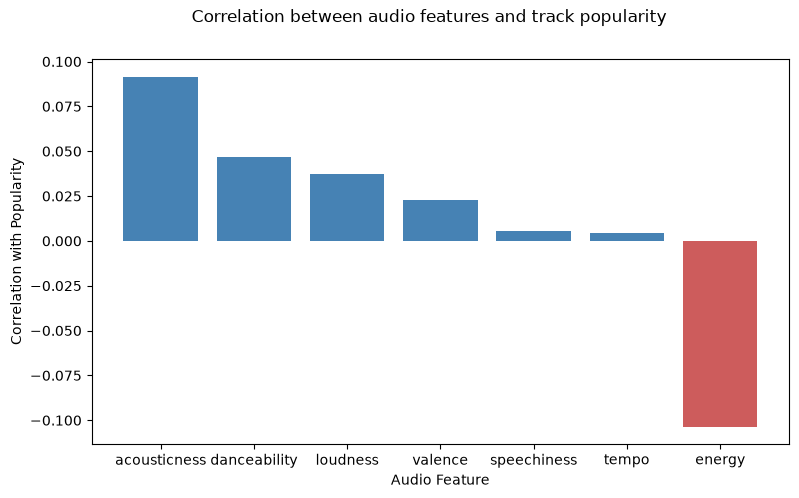

In [86]:
feature_corrs = pd.Series(feature_corrs).sort_values( ascending=False)
#plotting the bar chart 
plt.figure(figsize=(9, 5)) 

colours = ["steelblue" if v > 0 else "indianred" for v in feature_corrs.values]

plt.bar(x=feature_corrs.index, height=feature_corrs.values, color=colours)
plt.suptitle("Correlation between audio features and track popularity")
plt.xlabel("Audio Feature")
plt.ylabel("Correlation with Popularity")



### Q1 Findings: Audio features vs popularity

**How to read the chart**
- Each bar is one audio feature. Its height is the correlation with popularity, from -1 to 1.
- Blue bars (above zero): songs with more of that feature tend to be slightly more popular.
- Red bars (below zero): songs with more of that feature tend to be slightly less popular.
- Bigger bar means a stronger link. A bar near zero means almost no link.

**How I judged strength**
| Correlation (ignoring the sign) | Label |
|---|---|
| under 0.1 | negligible |
| 0.1 to 0.3 | weak |
| 0.3 to 0.5 | moderate |
| over 0.5 | strong |

**What the chart shows**
- Top positive: acousticness (about 0.09)
- Top negative: energy (about -0.10)
- Every bar is negligible or weak at most, so no single audio feature predicts popularity on its own.
- Correlation is not causation. These are patterns in the data, not reasons why songs succeed.

**Why is energy negative?**
- Energy and acousticness tend to move in opposite directions. Acoustic tracks are usually calmer and high energy tracks usually are not.
- So the two bars are probably telling a similar story from opposite ends: in this data, calmer and more acoustic songs are slightly more popular.

**What each feature means (Spotify's definitions)**
- **Acousticness:** how likely the track is to be acoustic, with no electronic sound
- **Danceability:** how suitable the track is for dancing (tempo, rhythm, beat strength)
- **Loudness:** overall volume of the track in decibels
- **Valence:** how positive or happy the track sounds
- **Speechiness:** how much of the track is spoken words, as in rap or podcasts
- **Tempo:** speed of the track in beats per minute
- **Energy:** how intense, fast and noisy the track feels

## Q2: Do the audio features of hit songs differ by genre?
- Heatmap

In [112]:
#defining what a hit actuall is:
cutoff = spotify_clean["track_popularity"].quantile(0.9)
#creating a dataframe of hits 
hits = spotify_clean[spotify_clean["track_popularity"] >= cutoff]

#explode the list of genres
hits_exploded = hits.explode("genres")
print(len(hits), "->", len(hits_exploded))   # should now go up

chosen = ["danceability", "energy", "valence", "acousticness"]
# Group the hit songs by genre, then average the chosen audio features within each genre.
genre_means = hits_exploded.groupby("genres")[chosen].mean()
genre_means

2972 -> 4067


,danceability,energy,valence,acousticness
genres,,,,
edm,0.662974,0.712132,0.505627,0.178671
latin,0.715023,0.693455,0.590679,0.223109
pop,0.656647,0.687005,0.517686,0.177358
r&b,0.684858,0.585496,0.476109,0.266688
rap,0.766865,0.642912,0.508664,0.177628
rock,0.539734,0.716205,0.552765,0.151732


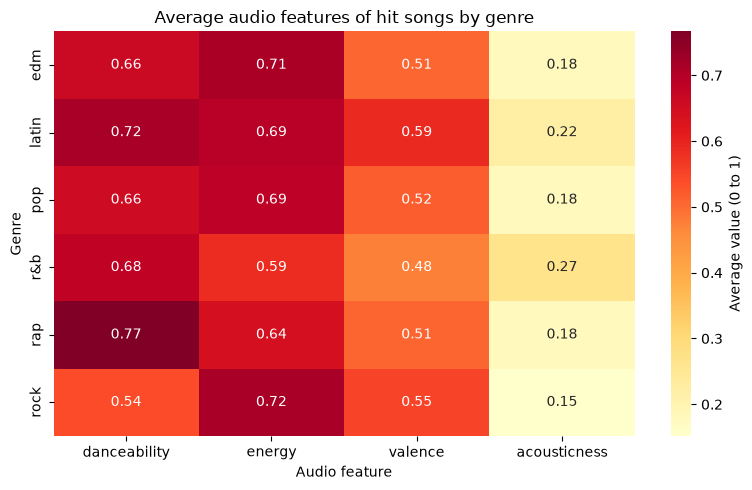

In [114]:
# Set the chart size (width, height in inches)
plt.figure(figsize=(8, 5))

# Draw the heatmap: rows are genres, columns are features, colour shows the average
sns.heatmap(
    genre_means,
    annot=True,                 # print the number inside each square
    fmt=".2f",                  # show numbers to 2 decimal places
    cmap="YlOrRd",              # colour scale: pale yellow = low, dark red = high
    cbar_kws={"label": "Average value (0 to 1)"}   # label for the colour bar on the side
)

# Title and axis labels
plt.title("Average audio features of hit songs by genre")
plt.xlabel("Audio feature")
plt.ylabel("Genre")

# Stop labels being cut off, then display the chart
plt.tight_layout()
plt.show()

### Q2 Findings: Do hit songs sound different by genre?

**How to read it**
- Each square is the average of a feature for hit songs (top 10% by popularity) in that genre.
- Darker means higher, lighter means lower. Compare down a column to rank genres on one feature.

**Answer: yes, but mostly in danceability**
- Danceability varies most between genres (0.54 for rock up to 0.77 for rap).
- Energy, valence and acousticness vary much less, so hits in every genre sit in a similar range.
- Hits are generally danceable (all above 0.5) and fairly energetic (all above 0.58), whatever the genre.

**Genre profiles at a glance**
| Genre | What stands out in its hits |
|---|---|
| Rap | Most danceable (0.77) |
| Latin | Highly danceable (0.72) and the most positive sounding (valence 0.59) |
| Rock | Least danceable (0.54), highest energy (0.72), least acoustic (0.15) |
| R&B | Calmest (energy 0.59), lowest valence (0.48), most acoustic (0.27) |
| EDM and Pop | Near identical, middling on everything |

**Takeaway for a record label**
- A danceable, energetic sound is a safe baseline for hits in most genres.
- Genre only changes the balance: more danceable for rap and Latin, more energy for rock, a calmer and more acoustic sound for R&B.

## Q3: Are songs that appear in multiple genres more popular than single-genre songs?
- boxplot 

In [119]:
# How many songs appear in 1, 2, 3, 4 or 5 genres?
spotify_clean["number_of_genres"].value_counts().sort_index()

number_of_genres
1    26669
2     1422
3      195
4       63
5        7
Name: count, dtype: int64

In [120]:
# Merge everything from 3 genres upwards into one group, so no group is tiny
spotify_clean["genre_group"] = spotify_clean["number_of_genres"].clip(upper=3)

# Replace the numbers with readable labels for the chart
spotify_clean["genre_group"] = spotify_clean["genre_group"].map(
    {1: "1 genre", 2: "2 genres", 3: "3 or more"}
)

# Check the new group sizes
spotify_clean["genre_group"].value_counts()

genre_group
1 genre      26669
2 genres      1422
3 or more      265
Name: count, dtype: int64

In [121]:
# Count, average and median popularity for each group
summary = spotify_clean.groupby("genre_group")["track_popularity"].agg(["count", "mean", "median"]).round(1)
summary

,count,mean,median
genre_group,,,
1 genre,26669,37.9,41.0
2 genres,1422,59.1,66.0
3 or more,265,75.2,81.0


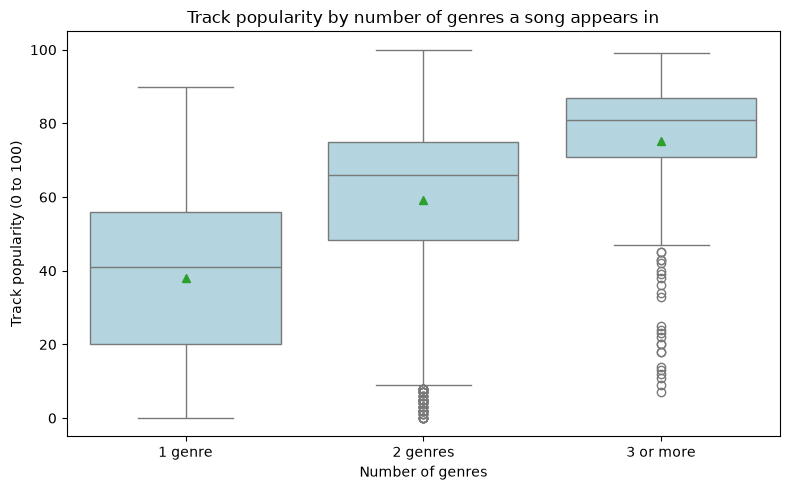

In [122]:
# Set the chart size
plt.figure(figsize=(8, 5))

# One box per group: the box is the middle 50% of songs, the line is the median,
# the green triangle is the mean (showmeans=True)
sns.boxplot(
    data=spotify_clean,
    x="genre_group",
    y="track_popularity",
    order=["1 genre", "2 genres", "3 or more"],   # keep the groups in a sensible order
    showmeans=True,
    color="lightblue"
)

# Title and axis labels
plt.title("Track popularity by number of genres a song appears in")
plt.xlabel("Number of genres")
plt.ylabel("Track popularity (0 to 100)")

# Tidy up and display
plt.tight_layout()
plt.show()

### Q3: Are songs in multiple genres more popular?

**How to read it**
- Each box shows the middle 50% of songs in that group. The line is the median and the green triangle is the mean.
- A higher box means more popular songs overall.

**Answer: yes, and the gap is large**
| Genres | Songs | Median popularity | Mean popularity |
|---|---|---|---|
| 1 genre | 26,669 | 41 | 37.9 |
| 2 genres | 1,422 | 66 | 59.1 |
| 3 or more | 265 | 81 | 75.2 |

- Popularity rises with every extra genre, from a median of 41 to 66 to 81.
- A song in 3 or more genres has a median about 40 points higher than a single genre song.
- Even the bottom of the "3 or more" box (about 71) sits above the median of single genre songs.

**Caveats**
- A song in more genres sits in more playlists, so it gets more exposure. The link could work in either direction: crossover songs may become popular, or popular songs may get added to more genre playlists.
- The "3 or more" group is small (265 songs, about 1% of the data), so treat its exact numbers with care. The pattern across all three groups is still clear.

## Final Summary

### Key findings
- **No single audio feature predicts popularity.** The strongest links were acousticness (+0.09) and energy (-0.10). Both are negligible to weak.
- **Hit songs share a broad sound.** In every genre, hits (top 10% by popularity) are danceable (above 0.5) and fairly energetic (above 0.58).
- **Genre changes the balance, not the basics.**
  - Rap hits are the most danceable (0.77).
  - Latin hits are the most positive sounding (valence 0.59).
  - Rock hits have the most energy (0.72) and the least acousticness (0.15).
  - R&B hits are the calmest (energy 0.59) and most acoustic (0.27).
- **Songs in more genres are far more popular.** Median popularity rises from 41 (1 genre) to 66 (2 genres) to 81 (3 or more).

### Trends
- Popularity climbs with every extra genre a song appears in.
- Across genres, danceability varies the most (0.54 for rock to 0.77 for rap). Energy, valence and acousticness vary much less.
- Acousticness is low for hits in every genre.

### Unexpected results
- **Energy is negatively linked to popularity.** Calmer, more acoustic tracks did slightly better, which goes against the idea that louder and more intense songs win.
- **Audio features matter far less than expected.** The biggest correlation was about 0.10, while genre spread was about 40 points of median popularity.
- **EDM and pop hits sound almost identical** on all four features.

### Recommendations
- Aim for a danceable, moderately energetic sound as a safe baseline in any genre.
- Adjust by genre: more danceable for rap and Latin, more energy for rock, calmer and more acoustic for R&B.
- Treat sound as a starting point only. Placement across several genres is the strongest pattern in the data, so crossover appeal is worth planning for.